In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load the file
path = "/content/latents_8_92160.pt"
data = torch.load(path, map_location=torch.device('cpu'))

# 2. Extract components
saved_latents = data["latents"]
# Assuming meta was saved as a tensor of [lat, lon]
saved_meta = data["meta"]
# 3. Print Summary Stats
print("--- 📂 File Inspection: latents.pt ---")
print(f"Total Samples:    {saved_latents.shape[0]}")
print(f"Latent Shape:     {saved_latents.shape[1]}")

# 4. Detailed Metric Breakdown (First 5 Samples)
print("\n--- 🛰️ Extracted Metrics Per Sample ---")
header = f"{'Idx':<5} | {'Lat':<10} | {'Lon':<10} | {'Cloud':<8} | {'Mean Elev':<10} | {'Std Elev':<10} | {'Range Elev':<10} |{'Time angle':<10} | Latent Head"
print(header)
print("-" * len(header))

for i in range(min(5, len(saved_latents))):
    # If you saved extra metrics in 'meta' or a separate dict, adjust indexing here:
    lat, lon, cloud_score, mean_elev, std_elev, range_elev, time = saved_meta[i].tolist()

    # Example of how to pull the first few values of the latent for a "fingerprint"
    # Fix: Flatten the tensor before taking the first 3 elements to get a flat list of numbers
    fingerprint = saved_latents[i].flatten()[:3].tolist()
    fp_str = ", ".join([f"{x:.3f}" for x in fingerprint])

    print(f"{i:<5} | {lat:<10.4f} | {lon:<10.4f} | {cloud_score:<8.4f} | {mean_elev:<10.2f} | {std_elev:<10.2f} | {range_elev:<10.2f} | {time:<10.2f} | {fp_str}")

# 5. Numerical Health Check
print("\n--- 🔍 Numerical Health Check ---")
lat_std = saved_latents.std(dim=0).mean().item()
print(f"Average Latent Std Dev: {lat_std:.6f}")

if lat_std < 1e-6:
    print("⚠️  CRITICAL: Latent vectors are identical across samples. Check model input/normalization.")
elif torch.isnan(saved_latents).any():
    print("❌ ERROR: NaNs detected in the saved tensors.")
else:
    print("✅ Latents appear diverse and healthy.")

--- 📂 File Inspection: latents.pt ---
Total Samples:    92160
Latent Shape:     192

--- 🛰️ Extracted Metrics Per Sample ---
Idx   | Lat        | Lon        | Cloud    | Mean Elev  | Std Elev   | Range Elev |Time angle | Latent Head
-----------------------------------------------------------------------------------------------------------
0     | 38.5666    | 111.5139   | 0.0000   | 1671.47    | 89.77      | 449.00     | 3.17       | -0.022, -0.279, -0.124
1     | 69.0627    | -91.5976   | 2.0000   | 183.71     | 8.12       | 48.00      | 2.90       | -0.271, 0.240, 0.037
2     | 11.4172    | 104.8779   | 0.1140   | 8.73       | 1.09       | 11.00      | 1.46       | -0.130, 0.179, -0.384
3     | 54.9352    | -72.0232   | 3.9155   | 439.94     | 18.00      | 75.00      | 5.89       | -0.402, 0.137, -0.133
4     | 26.2363    | 71.6623    | 0.0000   | 210.02     | 1.99       | 14.00      | 0.59       | -0.048, -0.314, -0.368

--- 🔍 Numerical Health Check ---
Average Latent Std Dev: 0.234

The idea is to train a simple model:
$$ \text{GeoEx}(x) = \text{MLP}(\vec{\lambda}\odot [R⋅(\vec{x}+\vec{t})])$$
with loss:
$$ L(y, x, \text{GeoEx}) = \text{MAE}(y,\text{GeoEx}(x))+\alpha \|\vec{\lambda}\|_1 + \beta \|(R\cdot R^T-I)\|_2$$
The tuple of $(R, \vec{t}, \vec{\lambda})$ represent the geometric transformation of data. As coefficients of $\vec{\lambda}$ are under $L_1$ regularization they represent 'turning off' majority of dimensions. Rotation $R$ and translation $\vec{t}$ define a affine transform.

In [3]:
class GeometryExtractor(nn.Module):
    def __init__(self, latent_dim, compressed_dim, feature_out_dim, geometry_learning = True):
        super(GeometryExtractor, self).__init__()

        self.geometry_learning = geometry_learning
        if self.geometry_learning:
          self.t_vec = nn.Parameter(torch.zeros(latent_dim))
          self.rotation_matrix = nn.Parameter(torch.eye(latent_dim))
          self.lambda_vec = nn.Parameter(torch.ones(latent_dim))

        # 4. Feature Extractor
        # Small MLP to decode the information from the identified subspace
        self.feature_extractor = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, feature_out_dim)
        )

    def forward(self, x):
        if self.geometry_learning:
          x = x + self.t_vec
          x = torch.matmul(x, self.rotation_matrix)
          x = x * self.lambda_vec

        # Feature Extraction
        logits = self.feature_extractor(x)
        return logits

In [4]:
X = saved_latents
y = saved_meta[:, 3]
print(X.shape, y.shape)

torch.Size([92160, 192]) torch.Size([92160])


In [18]:
# --- 2. Data Preparation ---
# Assuming X and y are already loaded as torch Tensors
def Geometry_Extraction(X, y, target_lambda = 2, verbose = 2, n_epochs = 100, beta_coeff = 1.35, alpha_coeff=1.35, out_dim = 1):
  dataset = TensorDataset(X, y.unsqueeze(1) if y.ndim == 1 else y)
  train_size = int(0.8 * len(dataset))
  test_size = len(dataset) - train_size
  train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

  train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
  test_loader = DataLoader(test_dataset, batch_size=256)

  # --- 3. Training Setup ---
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  H_model = GeometryExtractor(latent_dim=192, compressed_dim=192, feature_out_dim=out_dim).to(device)
  optimizer = optim.Adam(H_model.parameters(), lr=1e-3)

  # Hyperparameters for Regularization
  alpha_l1 = 0.01  # Sparsity strength
  beta_ortho = 0.01 # Orthogonality strength

  # --- 4. Training Loop ---
  epochs = n_epochs
  # Threshold for considering a lambda coefficient "active"
  sparsity_threshold = 1e-2

  if verbose > 0:
    print(f"{'Epoch':<6} | {'Total':<8} | {'MAE':<8} | {'L1':<8} | {'Ortho':<8} | {'Non-Zero'}")
    print("-" * 80)

  for epoch in range(epochs):
      H_model.train()
      # Metrics trackers
      running_mae, running_l1, running_ortho, running_total = 0, 0, 0, 0

      for batch_X, batch_y in train_loader:
          batch_X, batch_y = batch_X.to(device), batch_y.to(device)

          # Forward pass
          preds = H_model(batch_X)

          # Loss Components
          mae_loss = F.l1_loss(preds, batch_y) # For monitoring

          l1_reg = torch.norm(H_model.lambda_vec, p=1)

          R = H_model.rotation_matrix
          eye = torch.eye(R.size(0), device=device)
          ortho_dist = torch.norm(torch.matmul(R, R.t()) - eye, p=2)

          # Optimization Goal
          total_loss = mae_loss + (alpha_l1 * l1_reg) + (beta_ortho * ortho_dist)

          optimizer.zero_grad()
          total_loss.backward()
          optimizer.step()

          # Accumulate for printing
          running_total += total_loss.item()
          running_mae += mae_loss.item()
          running_l1 += alpha_l1*l1_reg.item()
          running_ortho += beta_ortho*ortho_dist.item()

      # Calculate Sparsity (count non-zero lambda coefficients)
      with torch.no_grad():
          non_zero_count = (H_model.lambda_vec.abs() > sparsity_threshold).sum().item()
          diff = torch.norm(torch.matmul(R, R.t()) - eye, p='fro')
          det = torch.det(R)

      if epoch == 1:
        n = len(train_loader)
        perc_mae = 100*running_mae / running_total
        perc_l1 = 100*running_l1 / running_total
        perc_ortho = 100*running_ortho / running_total
        alpha_l1 = alpha_l1 * 5 / perc_l1
        beta_ortho = beta_ortho * 5 / perc_ortho

      if epoch % 5 == 0:
          n = len(train_loader)
          perc_mae = 100*running_mae / running_total
          perc_l1 = 100*running_l1 / running_total
          perc_ortho = 100*running_ortho / running_total
          if non_zero_count > target_lambda:
            alpha_l1 = alpha_coeff*alpha_l1
          if diff > 1 or torch.abs(det-1) > 0.05 :
            beta_ortho = beta_coeff*beta_ortho
          if verbose > 1:
            print(f"{epoch:<6} | {running_total/n:<8.4f}  "
                  f"{perc_mae:<8.4f} | {perc_l1:<8.4f} | {perc_ortho:<8.4f} | "
                  f"{non_zero_count}/{H_model.lambda_vec.size(0)}")
  if verbose > 0:
    n = len(train_loader)
    R = H_model.rotation_matrix
    eye = torch.eye(R.size(0), device=device)
    perc_mae = 100*running_mae / running_total
    perc_l1 = 100*running_l1 / running_total
    perc_ortho = 100*running_ortho / running_total
    Orthonorm = torch.norm(torch.matmul(R, R.t()) - eye, p=2).item()
    Det = torch.det(R).item()
    print(f"{epoch:<6} | {running_total/n:<8.4f}  "
          f"{perc_mae:<8.4f} | {perc_l1:<8.4f} | {perc_ortho:<8.4f} | "
          f"{non_zero_count}/{H_model.lambda_vec.size(0)}")
    print('Dimensionality: ' + str(non_zero_count))
    print('Difference from orthogonality: ' + str(Orthonorm))
    print('Determinant of the rotation '+ str(Det))
  mae_loss = 0
  with torch.no_grad():
    for batch_X, batch_y in test_loader:
      batch_X, batch_y = batch_X.to(device), batch_y.to(device)
      preds = H_model(batch_X)
      mae_loss += F.l1_loss(preds, batch_y)
    mae_loss /= len(test_loader)
  if verbose > 0:
    print(f"Test MAE: {mae_loss.item()}")
  metrics = [mae_loss, non_zero_count, Det, Orthonorm]
  return H_model, metrics

def Probe_Training(X, y, n_epochs = 50, verbose = 2, out_dim = 1):
  dataset = TensorDataset(X, y.unsqueeze(1) if y.ndim == 1 else y)
  train_size = int(0.8 * len(dataset))
  test_size = len(dataset) - train_size
  train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

  train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
  test_loader = DataLoader(test_dataset, batch_size=256)

  # --- 3. Training Setup ---
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  H_model = GeometryExtractor(latent_dim=192, compressed_dim=192, feature_out_dim=2, geometry_learning=False).to(device)
  optimizer = optim.Adam(H_model.parameters(), lr=1e-3)

  # --- 4. Training Loop ---
  epochs = n_epochs


  for epoch in range(epochs):
      H_model.train()
      # Metrics trackers
      running_mae = 0
      running_total = 0

      for batch_X, batch_y in train_loader:
          batch_X, batch_y = batch_X.to(device), batch_y.to(device)

          # Forward pass
          preds = H_model(batch_X)

          # Loss Components
          mae_loss = F.l1_loss(preds, batch_y) # For monitoring

          # Optimization Goal
          total_loss = mae_loss

          optimizer.zero_grad()
          total_loss.backward()
          optimizer.step()

          # Accumulate for printing
          running_total += total_loss.item()
          running_mae += mae_loss.item()

      mae_loss = 0
      with torch.no_grad():
        for batch_X, batch_y in test_loader:
          batch_X, batch_y = batch_X.to(device), batch_y.to(device)
          preds = H_model(batch_X)
          mae_loss += F.l1_loss(preds, batch_y)
        mae_loss /= len(test_loader)
      if verbose > 0:
        print(f"Test MAE: {mae_loss.item()}")
      metrics = [mae_loss]
      return H_model, metrics

**Altitude Extraction**

In [11]:
H_model, metrics = Geometry_Extraction(X, y, target_lambda=2, verbose=2, beta_coeff=1.45, alpha_coeff=1.35)
_, probe_metrics = Probe_Training(X, y, verbose=0)

Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 590.1875  99.3696  | 0.3405   | 0.2899   | 192/192
5      | 503.6815  91.9213  | 5.2511   | 2.8275   | 192/192
10     | 453.3878  88.7746  | 7.3279   | 3.8975   | 192/192
15     | 443.1703  88.0603  | 7.9021   | 4.0377   | 187/192
20     | 437.5922  87.8501  | 7.8916   | 4.2584   | 146/192
25     | 434.0520  87.6859  | 7.8107   | 4.5034   | 89/192
30     | 434.3371  87.3197  | 7.9872   | 4.6931   | 58/192
35     | 436.8741  86.7618  | 8.4119   | 4.8263   | 41/192
40     | 439.5149  86.0528  | 9.0289   | 4.9184   | 29/192
45     | 447.1176  84.9555  | 10.0989  | 4.9456   | 22/192
50     | 457.0795  83.9615  | 11.1760  | 4.8625   | 19/192
55     | 462.6100  82.4937  | 12.7044  | 4.8019   | 14/192
60     | 474.3508  81.0968  | 14.3190  | 4.5842   | 12/192
65     | 485.7448  80.3351  | 15.4854  | 4.1795   | 11/192
70     | 492.0234  80.0265

In [14]:
print(metrics)
print(probe_metrics)

[tensor(415.9448, device='cuda:0'), 2, -1.0028386116027832, 0.014474602416157722]
[tensor(584.8461, device='cuda:0')]


Top 2 Lambda scales: [1.7347118  0.74751955]


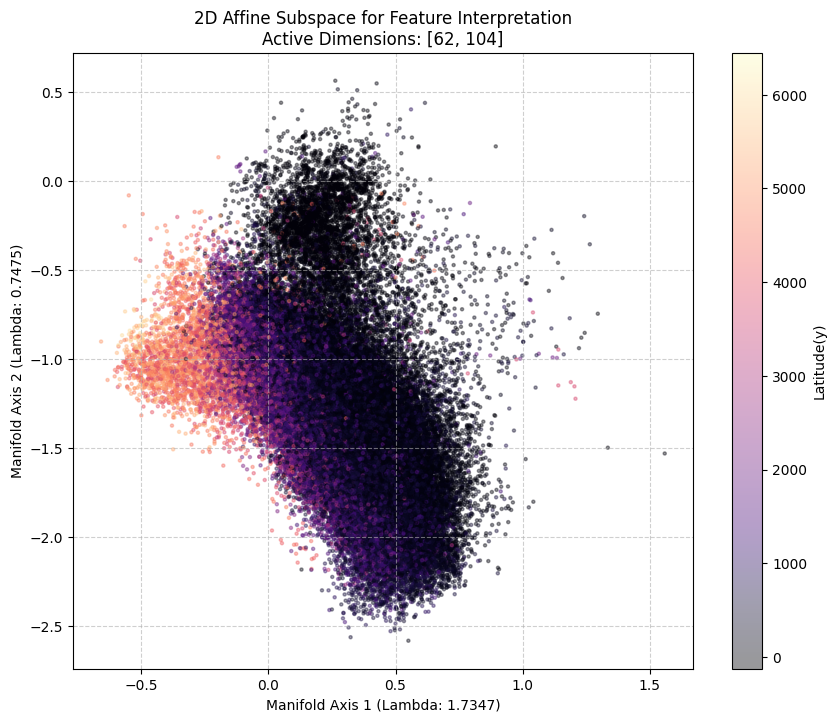

In [12]:
H_model.eval()
with torch.no_grad():
    # 1. Center the data using the learned translation
    X_centered = X.to(device) + H_model.t_vec

    # 2. Project onto the rotated space
    X_rotated = torch.matmul(X_centered, H_model.rotation_matrix)

    # 3. Get exactly the top 2 dimensions based on lambda magnitude
    top_2_indices = torch.argsort(H_model.lambda_vec.abs(), descending=True)[:2]
    active_dims = X_rotated[:, top_2_indices].cpu().numpy()

    # Get lambda values for these two to see their relative importance
    scales = H_model.lambda_vec[top_2_indices].cpu().numpy()
    print(f"Top 2 Lambda scales: {scales}")

# Plotting the 2D Manifold
plt.figure(figsize=(10, 8))
sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
            c=y.cpu().numpy(), cmap='magma', s=5, alpha=0.4)

plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
plt.colorbar(sc, label='Latitude(y)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

/content/latents_0_92160.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
99     | 633.0923  74.6937  | 25.1826  | 0.1236   | 3/192
Dimensionality: 3
Difference from orthogonality: 0.029305022209882736
Determinant of the rotation 1.0145341157913208
Test MAE: 467.287109375
Top 2 Lambda scales: [2.2878792 1.262681 ]


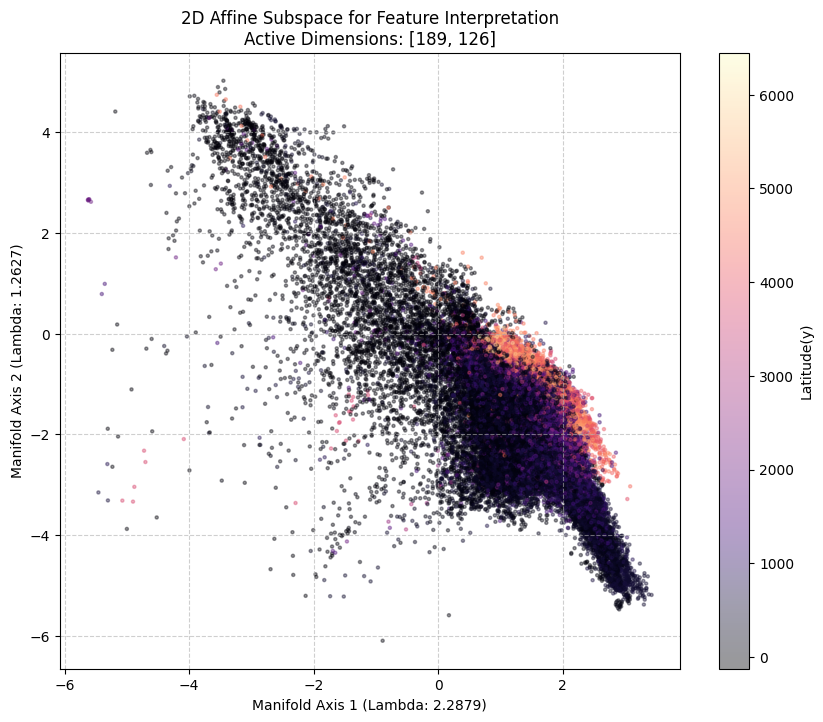

____________________________
/content/latents_2_92160.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
99     | 522.9159  81.9877  | 16.9413  | 1.0710   | 3/192
Dimensionality: 3
Difference from orthogonality: 0.15666259825229645
Determinant of the rotation -1.0837645530700684
Test MAE: 438.90826416015625
Top 2 Lambda scales: [1.4318235  0.59038335]


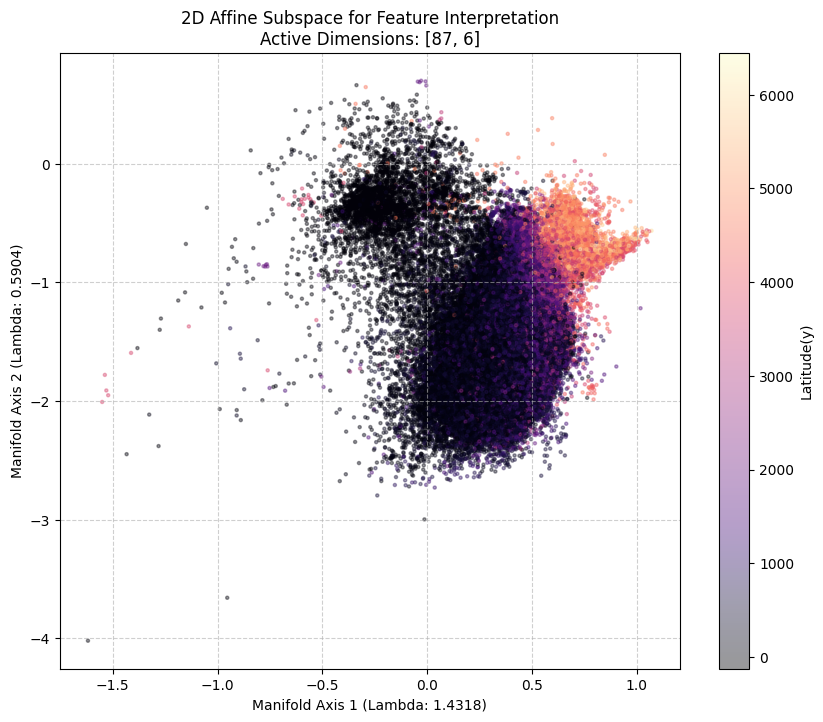

____________________________
/content/latents_4_92160.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
99     | 511.9023  79.7666  | 18.7969  | 1.4365   | 3/192
Dimensionality: 3
Difference from orthogonality: 0.22388659417629242
Determinant of the rotation 1.115523099899292
Test MAE: 410.5645446777344
Top 2 Lambda scales: [1.6749997  0.37001824]


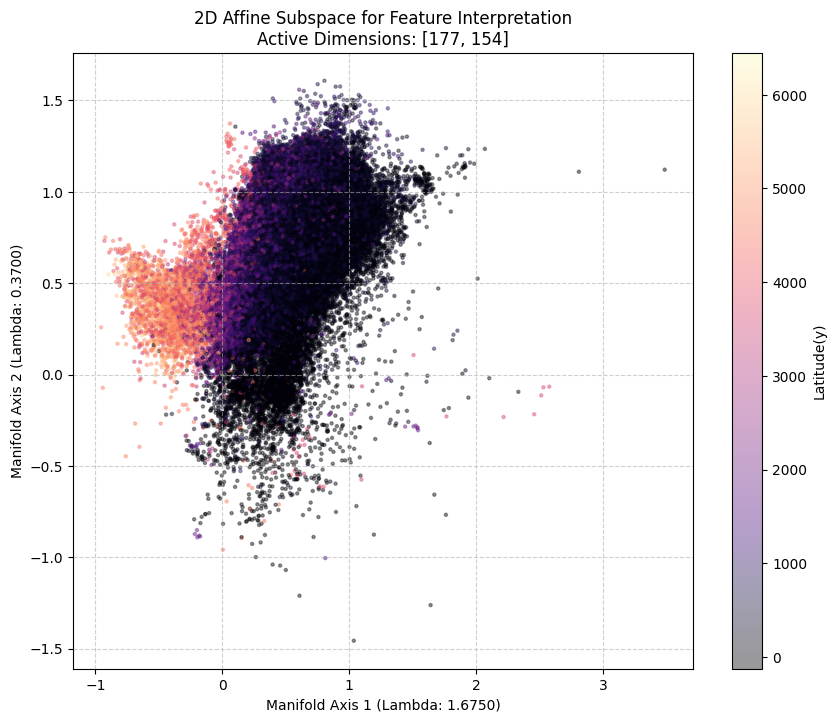

____________________________
/content/latents_6_92160.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
99     | 459.6422  84.5259  | 13.1099  | 2.3641   | 2/192
Dimensionality: 2
Difference from orthogonality: 0.443054735660553
Determinant of the rotation -1.2266058921813965
Test MAE: 391.0073547363281
Top 2 Lambda scales: [1.2602905 0.8409795]


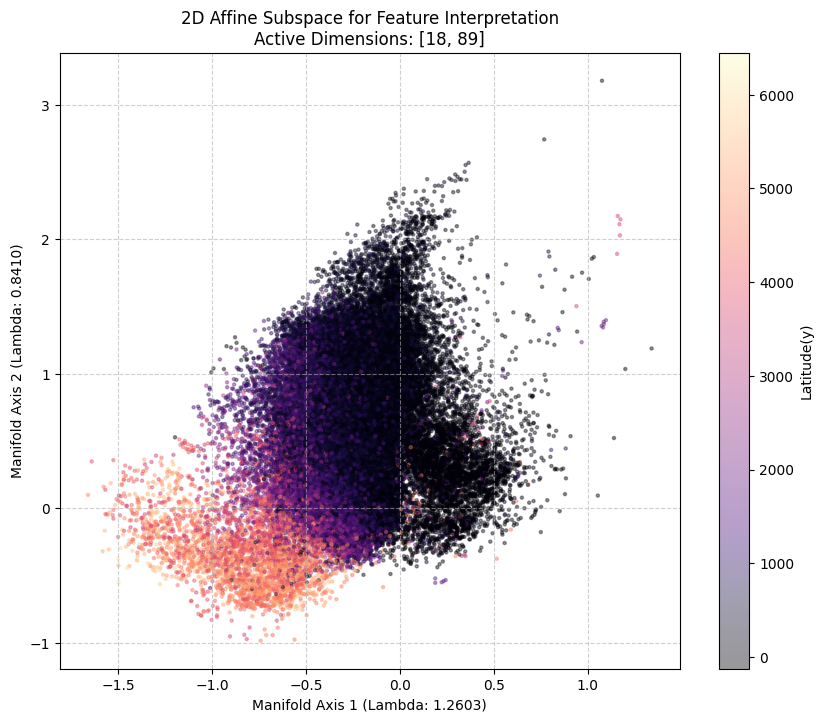

____________________________
/content/latents_8_92160.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
99     | 472.2357  86.4685  | 11.6597  | 1.8718   | 2/192
Dimensionality: 2
Difference from orthogonality: 0.3834637403488159
Determinant of the rotation -1.1939804553985596
Test MAE: 408.67401123046875
Top 2 Lambda scales: [1.8068359 0.1346599]


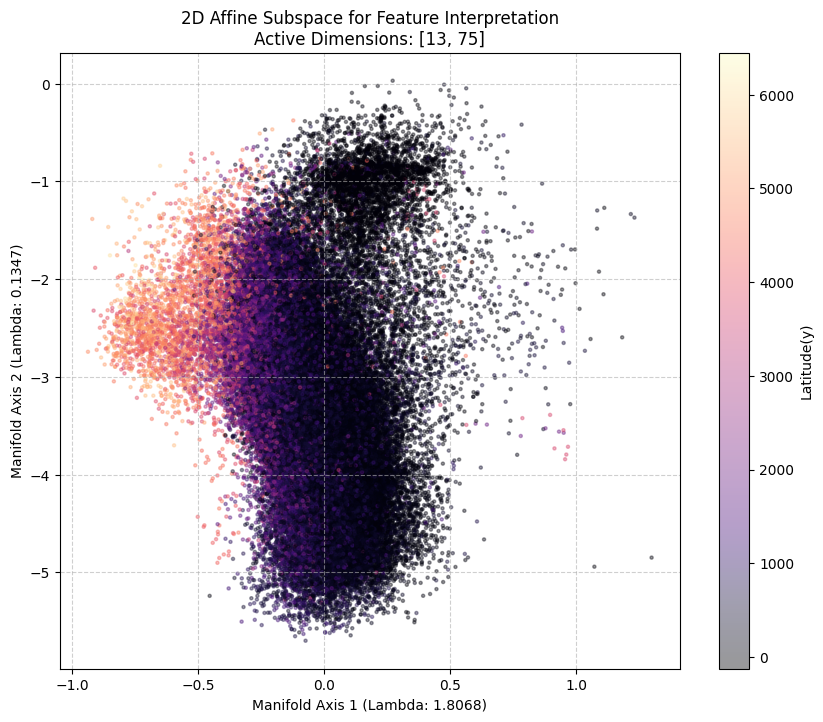

____________________________
/content/latents_10_92160.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
99     | 508.5971  91.0985  | 8.7652   | 0.1363   | 3/192
Dimensionality: 3
Difference from orthogonality: 0.03076721914112568
Determinant of the rotation -1.0164116621017456
Test MAE: 463.2696838378906
Top 2 Lambda scales: [0.9410156  0.12225248]


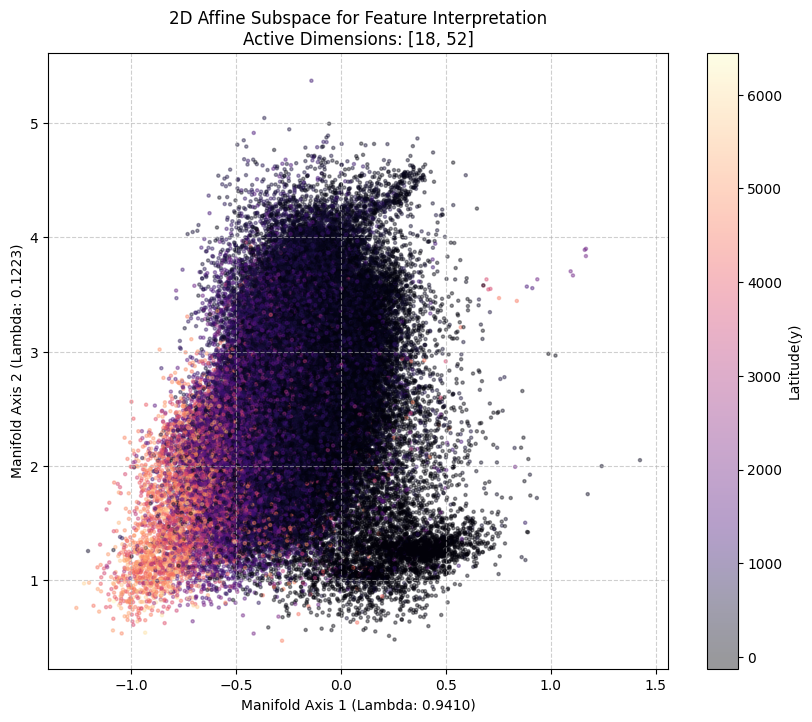

____________________________
/content/latents_12_92160.pt
Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
99     | 520.6825  93.9046  | 6.0213   | 0.0742   | 2/192
Dimensionality: 2
Difference from orthogonality: 0.01657875068485737
Determinant of the rotation -1.007102608680725
Test MAE: 487.3043212890625
Top 2 Lambda scales: [0.8170829  0.24324732]


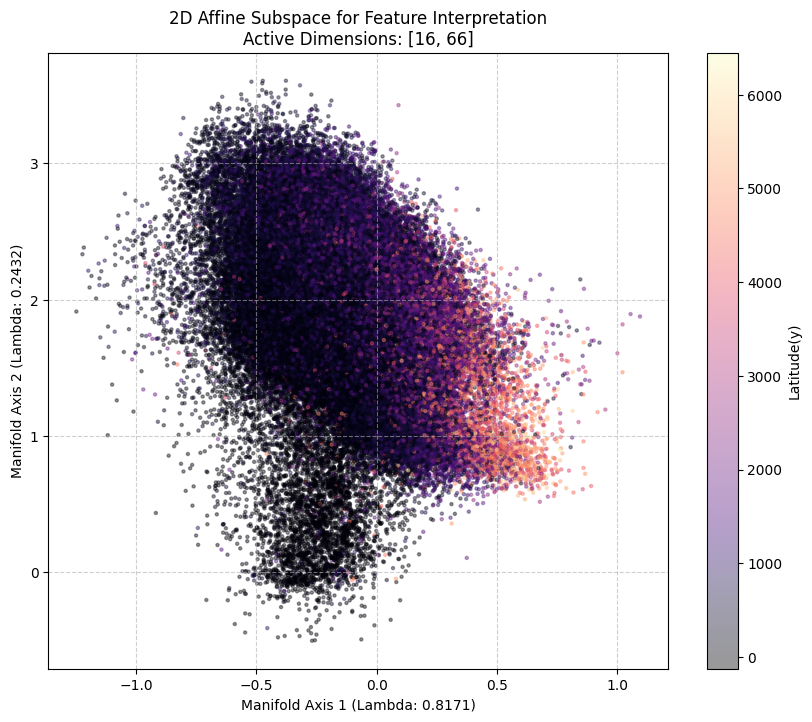

____________________________


In [ ]:
idx = [0, 2, 4, 6, 8, 10, 12]
overall_metrics = []
target_lambda = 2
probe_mae = []
for id in idx:
  path = "/content/latents_" + str(id) + "_92160.pt"
  print(path)
  data = torch.load(path, map_location=device)
  saved_latents = data["latents"]
  saved_meta = data["meta"]
  X = saved_latents
  y = saved_meta[:, 3]
  H_model, metrics = Geometry_Extraction(X, y, target_lambda=target_lambda, verbose=1)
  overall_metrics.append(metrics)
  _, probe_metrics = Probe_Training(X, y, verbose=0)
  probe_mae.append(probe_metrics)
  H_model.eval()
  with torch.no_grad():
      X_centered = X.to(device) + H_model.t_vec
      X_rotated = torch.matmul(X_centered, H_model.rotation_matrix)

      top_2_indices = torch.argsort(H_model.lambda_vec.abs(), descending=True)[:2]
      active_dims = X_rotated[:, top_2_indices].cpu().numpy()

      scales = H_model.lambda_vec[top_2_indices].cpu().numpy()
      print(f"Top 2 Lambda scales: {scales}")

  plt.figure(figsize=(10, 8))
  sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
              c=y.cpu().numpy(), cmap='magma', s=5, alpha=0.4)

  plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
  plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
  plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
  plt.colorbar(sc, label='Latitude(y)')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()
  print("_"*28)

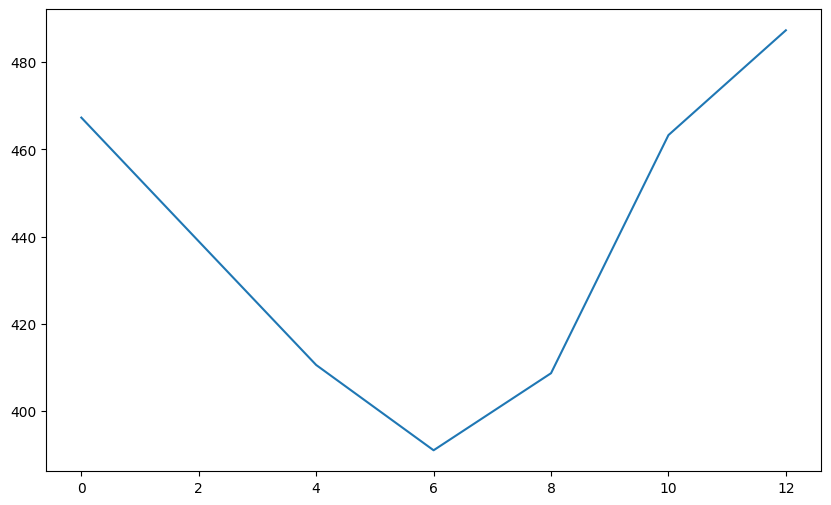

In [ ]:
processed_metrics = []
for m in overall_metrics:
    # m[0] is the tensor, move to cpu and get its scalar value
    # m[1:] are already Python numbers or can be directly converted by numpy
    processed_metrics.append([m[0].cpu().item()] + m[1:])
metrics = np.array(processed_metrics)
plt.figure(figsize=(10, 6))
plt.plot(idx, metrics[:,0])

**Time of the season extraction** -> Circular geometry

In [13]:
lats = saved_meta[:, 0]
alts = saved_meta[:, 3]
X = saved_latents[(lats > 15) & (lats < 66) & (alts < 4000)]
times = saved_meta[:, -1][(lats > 15) & (lats < 66) & (alts < 4000)]
sins = torch.sin(times)
coss = torch.cos(times)
y = torch.stack([sins, coss], dim=1)
print(X.shape, y.shape)

torch.Size([50276, 192]) torch.Size([50276, 2])


In [28]:
model, metrics = Geometry_Extraction(X, y, target_lambda=2, verbose=2, beta_coeff=1.25, alpha_coeff=1.45, out_dim = 2)
_, probe_metrics = Probe_Training(X, y, verbose=2, out_dim=2)

Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.3122    23.2273  | 76.5565  | 0.2162   | 192/192
5      | 0.5834    79.4805  | 17.6896  | 2.8299   | 192/192
10     | 0.5719    77.9472  | 19.2677  | 2.7850   | 192/192
15     | 0.5222    85.1697  | 12.3076  | 2.5227   | 162/192
20     | 0.4909    90.2400  | 7.4944   | 2.2657   | 60/192
25     | 0.4797    91.7448  | 6.2598   | 1.9953   | 36/192
30     | 0.4740    92.1265  | 6.1237   | 1.7498   | 23/192
35     | 0.4717    92.0522  | 6.3118   | 1.6359   | 20/192
40     | 0.4718    92.1777  | 6.2147   | 1.6076   | 16/192
45     | 0.4714    92.3488  | 6.3115   | 1.3396   | 14/192
50     | 0.4714    92.2869  | 6.4457   | 1.2673   | 12/192
55     | 0.4749    92.3087  | 6.4931   | 1.1981   | 10/192
60     | 0.4776    92.0365  | 6.8406   | 1.1229   | 9/192
65     | 0.4816    91.6002  | 7.3132   | 1.0866   | 8/192
70     | 0.4865    91.1431  |

Top 2 Lambda scales: [0.01699024 0.0146383 ]


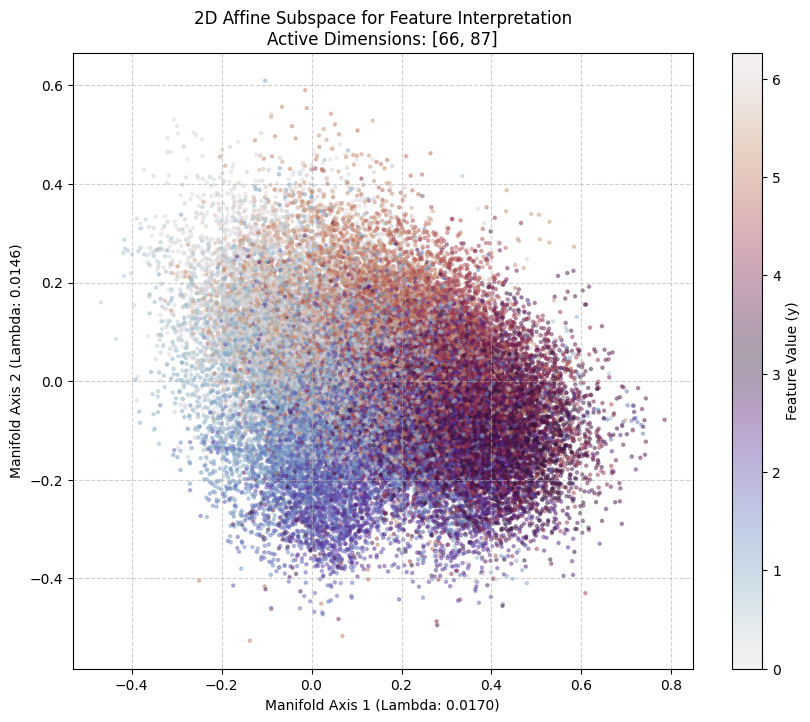

In [29]:
model.eval()
with torch.no_grad():
    # 1. Center the data using the learned translation
    X_centered = X.to(device) + model.t_vec

    # 2. Project onto the rotated space
    X_rotated = torch.matmul(X_centered, model.rotation_matrix)

    # 3. Get exactly the top 2 dimensions based on lambda magnitude
    top_2_indices = torch.argsort(model.lambda_vec.abs(), descending=True)[:2]
    active_dims = X_rotated[:, top_2_indices].cpu().numpy()

    # Get lambda values for these two to see their relative importance
    scales = model.lambda_vec[top_2_indices].cpu().numpy()
    print(f"Top 2 Lambda scales: {scales}")

# Plotting the 2D Manifold
plt.figure(figsize=(10, 8))
sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
            c=times.cpu().numpy(), cmap='twilight', s=5, alpha=0.4)

plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
plt.colorbar(sc, label='Feature Value (y)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Time of the season extraction** -> Linear geometry -> It fails!!!

In [31]:
model, metrics = Geometry_Extraction(X,times, target_lambda=2, verbose=2, beta_coeff=1.3, alpha_coeff=1.35, out_dim = 1)

Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 3.3214    45.8545  | 53.5890  | 0.5565   | 192/192
5      | 1.5087    90.3431  | 8.9318   | 0.7251   | 192/192
10     | 1.4647    90.5459  | 8.5793   | 0.8748   | 192/192
15     | 1.3750    94.9437  | 4.5046   | 0.5517   | 95/192
20     | 1.3349    96.2301  | 3.3407   | 0.4292   | 46/192
25     | 1.3219    96.2766  | 3.3376   | 0.3859   | 26/192
30     | 1.3128    96.0545  | 3.6125   | 0.3330   | 23/192
35     | 1.3101    95.7096  | 3.9612   | 0.3291   | 17/192
40     | 1.3070    95.2103  | 4.4860   | 0.3037   | 14/192
45     | 1.3074    94.7393  | 4.9994   | 0.2613   | 11/192
50     | 1.3128    94.2799  | 5.4775   | 0.2427   | 11/192
55     | 1.3145    93.9953  | 5.7877   | 0.2170   | 10/192
60     | 1.3236    93.8340  | 5.9527   | 0.2134   | 7/192
65     | 1.3254    93.3435  | 6.4621   | 0.1944   | 6/192
70     | 1.3309    93.0617  | 

**Latitude** -> Linear geometry

In [32]:
X = saved_latents
y = saved_meta[:, 0]
print(X.shape, y.shape)

torch.Size([92160, 192]) torch.Size([92160])


In [38]:
Lat_model, metrics = Geometry_Extraction(X, y, target_lambda=2, verbose=2, beta_coeff=1.4, alpha_coeff=1.45)

Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 22.8547   90.1112  | 7.9070   | 1.9818   | 192/192
5      | 16.9864   92.1349  | 5.0462   | 2.8189   | 192/192
10     | 16.7091   91.8249  | 5.8310   | 2.3441   | 179/192
15     | 16.5366   92.1206  | 5.8073   | 2.0721   | 147/192
20     | 16.2202   92.6895  | 5.4135   | 1.8970   | 100/192
25     | 16.0006   93.5075  | 4.8000   | 1.6925   | 64/192
30     | 15.7116   94.1456  | 4.3634   | 1.4911   | 32/192
35     | 15.6348   94.1419  | 4.6384   | 1.2197   | 19/192
40     | 15.7207   93.8389  | 5.3436   | 0.8175   | 13/192
45     | 15.8532   93.4447  | 6.2786   | 0.2767   | 10/192
50     | 15.7992   92.9064  | 7.0196   | 0.0740   | 6/192
55     | 15.9394   91.6011  | 8.3293   | 0.0696   | 5/192
60     | 16.1469   90.5568  | 9.3706   | 0.0726   | 4/192
65     | 16.3333   89.6648  | 10.2610  | 0.0741   | 4/192
70     | 16.5223   89.5339  | 

Top 2 Lambda scales: [0.1547091  0.04300152]


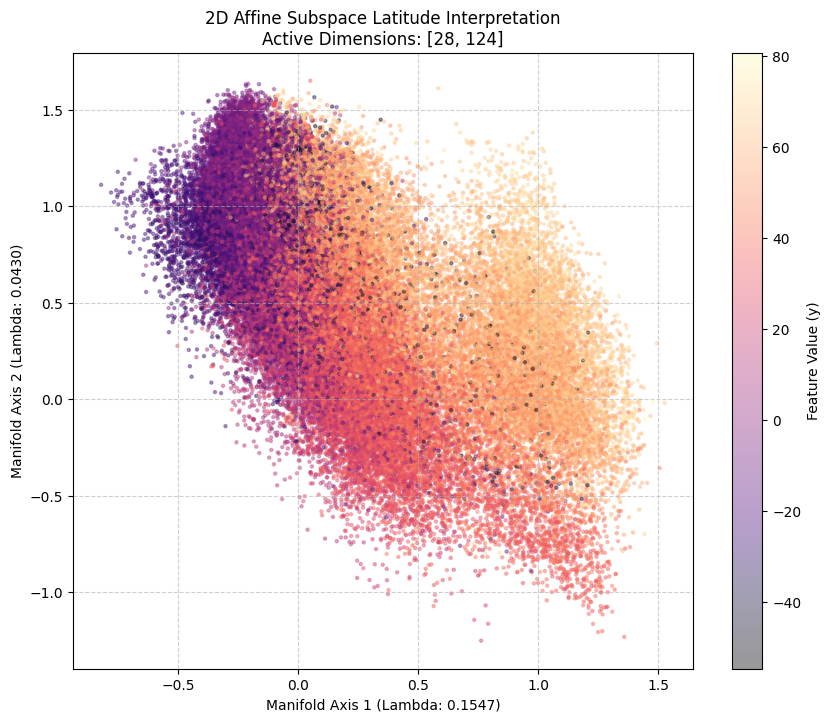

In [39]:
Lat_model.eval()
with torch.no_grad():
    # 1. Center the data using the learned translation
    X_centered = X.to(device) + Lat_model.t_vec

    # 2. Project onto the rotated space
    X_rotated = torch.matmul(X_centered, Lat_model.rotation_matrix)

    # 3. Get exactly the top 2 dimensions based on lambda magnitude
    top_2_indices = torch.argsort(Lat_model.lambda_vec.abs(), descending=True)[:2]
    active_dims = X_rotated[:, top_2_indices].cpu().numpy()

    # Get lambda values for these two to see their relative importance
    scales = Lat_model.lambda_vec[top_2_indices].cpu().numpy()
    print(f"Top 2 Lambda scales: {scales}")

# Plotting the 2D Manifold
plt.figure(figsize=(10, 8))
sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
            c=y.cpu().numpy(), cmap='magma', s=5, alpha=0.4)

plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
plt.title(f"2D Affine Subspace Latitude Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
plt.colorbar(sc, label='Feature Value (y)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [50]:
lats = saved_meta[:, 0]
X = saved_latents
longs = np.pi * (saved_meta[:, 1] + 180) / 180
sins = torch.sin(longs)
coss = torch.cos(longs)
y = torch.stack([sins, coss], dim=1)
print(X.shape, y.shape)

torch.Size([92160, 192]) torch.Size([92160, 2])


In [52]:
model, metrics = Geometry_Extraction(X, y, target_lambda=2, verbose=2, beta_coeff=1.25, alpha_coeff=1.4, out_dim = 2)

Epoch  | Total    | MAE      | L1       | Ortho    | Non-Zero
--------------------------------------------------------------------------------
0      | 2.2002    25.0402  | 74.8337  | 0.1261   | 192/192
5      | 0.5588    88.5974  | 9.0749   | 2.3277   | 192/192
10     | 0.5154    94.1440  | 3.5949   | 2.2611   | 83/192
15     | 0.5007    95.2257  | 2.9245   | 1.8498   | 40/192
20     | 0.4936    95.4358  | 2.9910   | 1.5732   | 33/192
25     | 0.4906    95.5197  | 3.0493   | 1.4310   | 23/192
30     | 0.4903    95.4295  | 3.2598   | 1.3107   | 20/192
35     | 0.4886    95.2904  | 3.4982   | 1.2114   | 17/192
40     | 0.4881    95.0788  | 3.7658   | 1.1555   | 14/192
45     | 0.4903    94.8425  | 4.0432   | 1.1143   | 12/192
50     | 0.4917    94.5430  | 4.3589   | 1.0982   | 11/192
55     | 0.4942    94.2079  | 4.7028   | 1.0893   | 11/192
60     | 0.4969    93.8852  | 5.0440   | 1.0708   | 10/192
65     | 0.4995    93.5838  | 5.3688   | 1.0474   | 9/192
70     | 0.5032    93.2157  | 

Top 2 Lambda scales: [0.01723893 0.01304925]


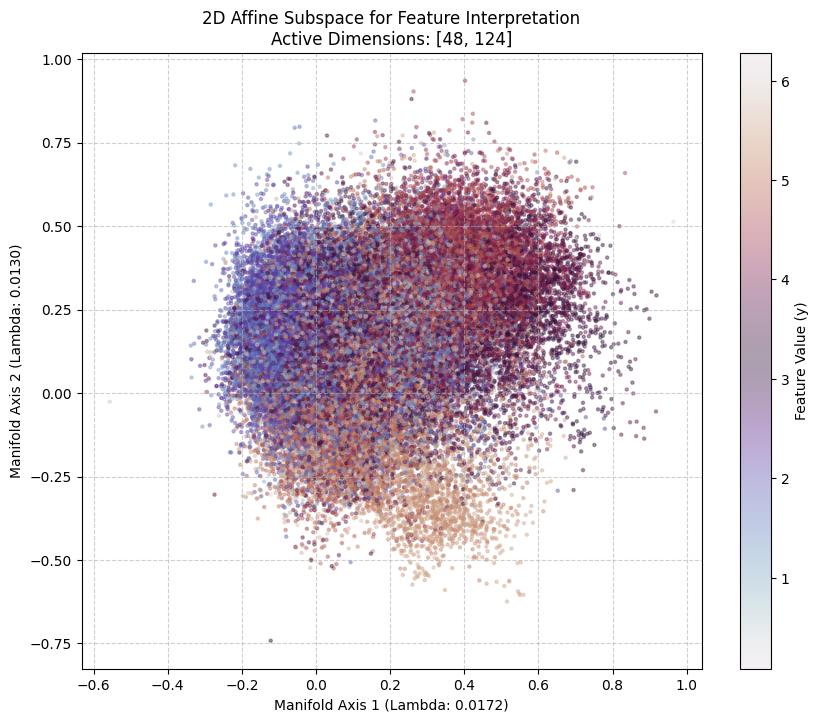

In [54]:
model.eval()
with torch.no_grad():
    # 1. Center the data using the learned translation
    X_centered = X.to(device) + model.t_vec

    # 2. Project onto the rotated space
    X_rotated = torch.matmul(X_centered, model.rotation_matrix)

    # 3. Get exactly the top 2 dimensions based on lambda magnitude
    top_2_indices = torch.argsort(model.lambda_vec.abs(), descending=True)[:2]
    active_dims = X_rotated[:, top_2_indices].cpu().numpy()

    # Get lambda values for these two to see their relative importance
    scales = model.lambda_vec[top_2_indices].cpu().numpy()
    print(f"Top 2 Lambda scales: {scales}")

# Plotting the 2D Manifold
plt.figure(figsize=(10, 8))
sc = plt.scatter(active_dims[:, 0], active_dims[:, 1],
            c=longs.cpu().numpy(), cmap='twilight', s=5, alpha=0.4)

plt.xlabel(f"Manifold Axis 1 (Lambda: {scales[0]:.4f})")
plt.ylabel(f"Manifold Axis 2 (Lambda: {scales[1]:.4f})")
plt.title(f"2D Affine Subspace for Feature Interpretation\nActive Dimensions: {top_2_indices.tolist()}")
plt.colorbar(sc, label='Feature Value (y)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()